In [20]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.optimize as spopt
import numpy.ma as ma
from tqdm import tqdm
import pandas as pd
import glob, os
from astropy.time import Time
import sys
from matplotlib.patches import Rectangle
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.ticker import MultipleLocator

In [2]:
def get_station_colors():
    cols = ['#4dac26', '#377eb8', '#e66101', 'darkorchid', 'black', '#d95f02']
    return {'on': cols[0], 'wb': cols[1], 'tr': cols[2], 'st': cols[3], 'fast': cols[4], 'dw':cols[5]}

In [3]:
def dummy_maker(telescope, obs_code, df_temp):
    #"Function to make an overview of begin, end and frequency setup per observations"
    #"duplicates are allowed in this df"

    dummy_data = {}
    dummy_data["Telescope"] = telescope
    dummy_data["obs_code"] = obs_code

    dummy_data["mjd_start"] = np.min(df_temp["MJD_start_time"])
    dummy_data["mjd_end"] = np.max(df_temp["MJD_end_time"])

    bandwidth = df_temp["Total_Bandwidth_(MHz)"].values[0]
    nchan = df_temp["Number_of_channels"].values[0]

    #Calculate half the channelwidth
    half_channel_width = (bandwidth/nchan) / 2

    #frequency setup of observation
    dummy_data["bandwidth"] = bandwidth
    #dummy_data["nchan"] = nchan

    dummy_data["cent_f"] = df_temp["Central_freq_(MHz)"].values[0]
    dummy_data["low_c_l"] = df_temp["Low_channel_(MHz)"].values[0] - half_channel_width
    dummy_data["high_c_h"] = df_temp["High_channel_(MHz)"].values[0] + half_channel_width

    rec_time_s = np.sum(df_temp["total_obs_time_s"])
    dummy_data["rec_time_s"] = rec_time_s
    dummy_data["rec_time_m"] = rec_time_s / 60.
    dummy_data["rec_time_h"] = rec_time_s / 3600.
    dummy_data["rec_time_d"] = rec_time_s / (3600. * 24.)
    return dummy_data


In [5]:
def reduce_df(save_bool=False):
    "Function to load in the main dataframe and reduce to a df which can be used for the making of this plot"
    "This smaller dataframe is based per observation instead of per scan"
    
    big_df = pd.read_csv("../dbs/mkt_fullcampaign_v4.csv", sep=",", header=0, index_col=0, \
                            na_values='NA', engine='python')
    big_df = big_df.reset_index(drop=True)
    
    dict_list = []

    #list of all telescopes that were used
    #telescopes2 = list(set(big_df["Telescope"]))
    telescopes = big_df["Telescope"].unique()

    for single_telescope in telescopes:
        big_df_telescope = big_df[(big_df["Telescope"] == single_telescope)]
        
        #list of all the observations code that were used for that specific telescope
        observations = list(set(big_df_telescope["scan_name"]))
        
        #observations.sort()
        for s_observation in observations:
            #Create a temp df for a single telescope for a single observation
            #Even though this df only had source r67, I filter on it as a failsave
            df_temp = big_df_telescope[(big_df_telescope["scan_name"] == s_observation)]

            # some runs have more than one frequency setup, need to account for this
            freqs = df_temp["Central_freq_(MHz)"].unique()
            
            #If there are more than 1 frequency setup in a single observations -- switching frequencies
            if len(df_temp["Central_freq_(MHz)"].unique()) > 1 :

                print(f"!!!Splitting the dataframe {s_observation} because of different frequency setup!!!")
                #When the frequency changes it will get a new numbers in the dataframe, this way we can utilze the groupby method of pandas to loop over the differt dfs
                #example: https://stackoverflow.com/questions/64163984/how-to-split-a-dataframe-each-time-a-string-value-changes-in-a-column
                df_temp['group'] = df_temp['Central_freq_(MHz)'].ne(df_temp['Central_freq_(MHz)'].shift()).cumsum()
                df_temp = df_temp.groupby('group')

                for name, df_temp_freqs in df_temp:

                    dummy_data = dummy_maker(single_telescope, s_observation, df_temp_freqs)
                    dict_list.append(dummy_data)

            else:

                dummy_data = dummy_maker(single_telescope, s_observation, df_temp)
                dict_list.append(dummy_data)
            
    df_reduced = pd.DataFrame(dict_list)    
    df_reduced = df_reduced.sort_values(by="mjd_start")
    df_reduced = df_reduced.reset_index(drop=True)
    
    display(df_reduced)
        
    if save_bool == True:
        csv_obs = "../dbs/r240616d_camp_reduced_V4.csv"
        df_reduced.to_csv(csv_obs, sep=",", header=True, index=True, na_rep='NA')
        print("reduced campaign saved")
    
    return df_reduced

df_reduced = reduce_df(save_bool=False)

,Telescope,obs_code,mjd_start,mjd_end,bandwidth,cent_f,low_c_l,high_c_h,rec_time_s,rec_time_m,rec_time_h,rec_time_d
0,wb,p55011,60496.949097,60497.086156,128.0000,1271.000000,1207.000000,1335.000000,11657.937730,194.298962,3.238316,0.134930
1,Nancay,nuppi_60497_1949-2512_296603,60497.019618,60497.052047,512.0000,1484.000000,1228.000000,1740.000000,2801.848317,46.697472,0.778291,0.032429
2,stk,r240619d_60497_1,60497.933105,60498.089536,98.4375,1381.464844,1332.246094,1430.683594,13515.662295,225.261038,3.754351,0.156431
3,wb,p55012,60497.946319,60498.083377,64.0000,332.000000,300.000000,364.000000,11659.380354,194.323006,3.238717,0.134947
4,wb,p55013,60498.943530,60499.080599,64.0000,332.000000,300.000000,364.000000,11663.574656,194.392911,3.239882,0.134995
...,...,...,...,...,...,...,...,...,...,...,...,...
414,Nancay,nuppi_60596_1949-2512_298398,60596.734838,60596.769548,512.0000,1484.000000,1228.000000,1740.000000,2998.923260,49.982054,0.833034,0.034710
415,wb,p55107,60597.673981,60597.811040,128.0000,1271.000000,1207.000000,1335.000000,11652.825924,194.213765,3.236896,0.134871
416,wb,p55108,60598.670625,60598.807695,128.0000,1271.000000,1207.000000,1335.000000,11653.743424,194.229057,3.237151,0.134881
417,wb,p55109,60599.667847,60599.804918,128.0000,1271.000000,1207.000000,1335.000000,11657.806657,194.296778,3.238280,0.134928


In [17]:
def df_obs_times():

    # Creating the DataFrame with the specified values and column name

    #For Nancay I will take the middle of the observation
    df_nrt = df_reduced[df_reduced["Telescope"] == "Nancay"].copy()
    df_nrt["mjd_middle"] = df_nrt["mjd_start"] + df_nrt["rec_time_d"]
    
    mjds_nrt = df_nrt["mjd_middle"].values
    mjds_nrt_below_60538 = mjds_nrt[mjds_nrt < 60538]

    #On these days, HyperFlash already detected bursts, so we don't need a red triangle on these days
    values_to_drop = [60512.00890564, 60537.93859963]
    mjds_filtered = mjds_nrt_below_60538[~np.isin(mjds_nrt_below_60538, values_to_drop)]

    mjd_hyperflash = np.array([60511.98778150463, 60526.88976345613, 60526.88976511574, 60530.87650308863, 60535.939572838346, 60536.87820357657, \
                            60536.87820587847, 60537.88252653935, 60553.89310871119, 60553.89310871119, 60557.86049664352, 60557.907627187495,\
                            60562.88865997685, 60569.75872295139])

    combined_mjds = np.concatenate([mjds_filtered, mjd_hyperflash])
    combined_mjds = np.sort(combined_mjds)

    df = pd.DataFrame({'mjd_tdb_inf_freq': combined_mjds})

    return df
    
df_obs_times()

,mjd_tdb_inf_freq
0,60497.052047
1,60503.026350
2,60511.987782
3,60512.008906
4,60516.995943
5,60520.984049
6,60526.889763
7,60526.889765
8,60530.876503
9,60535.939573


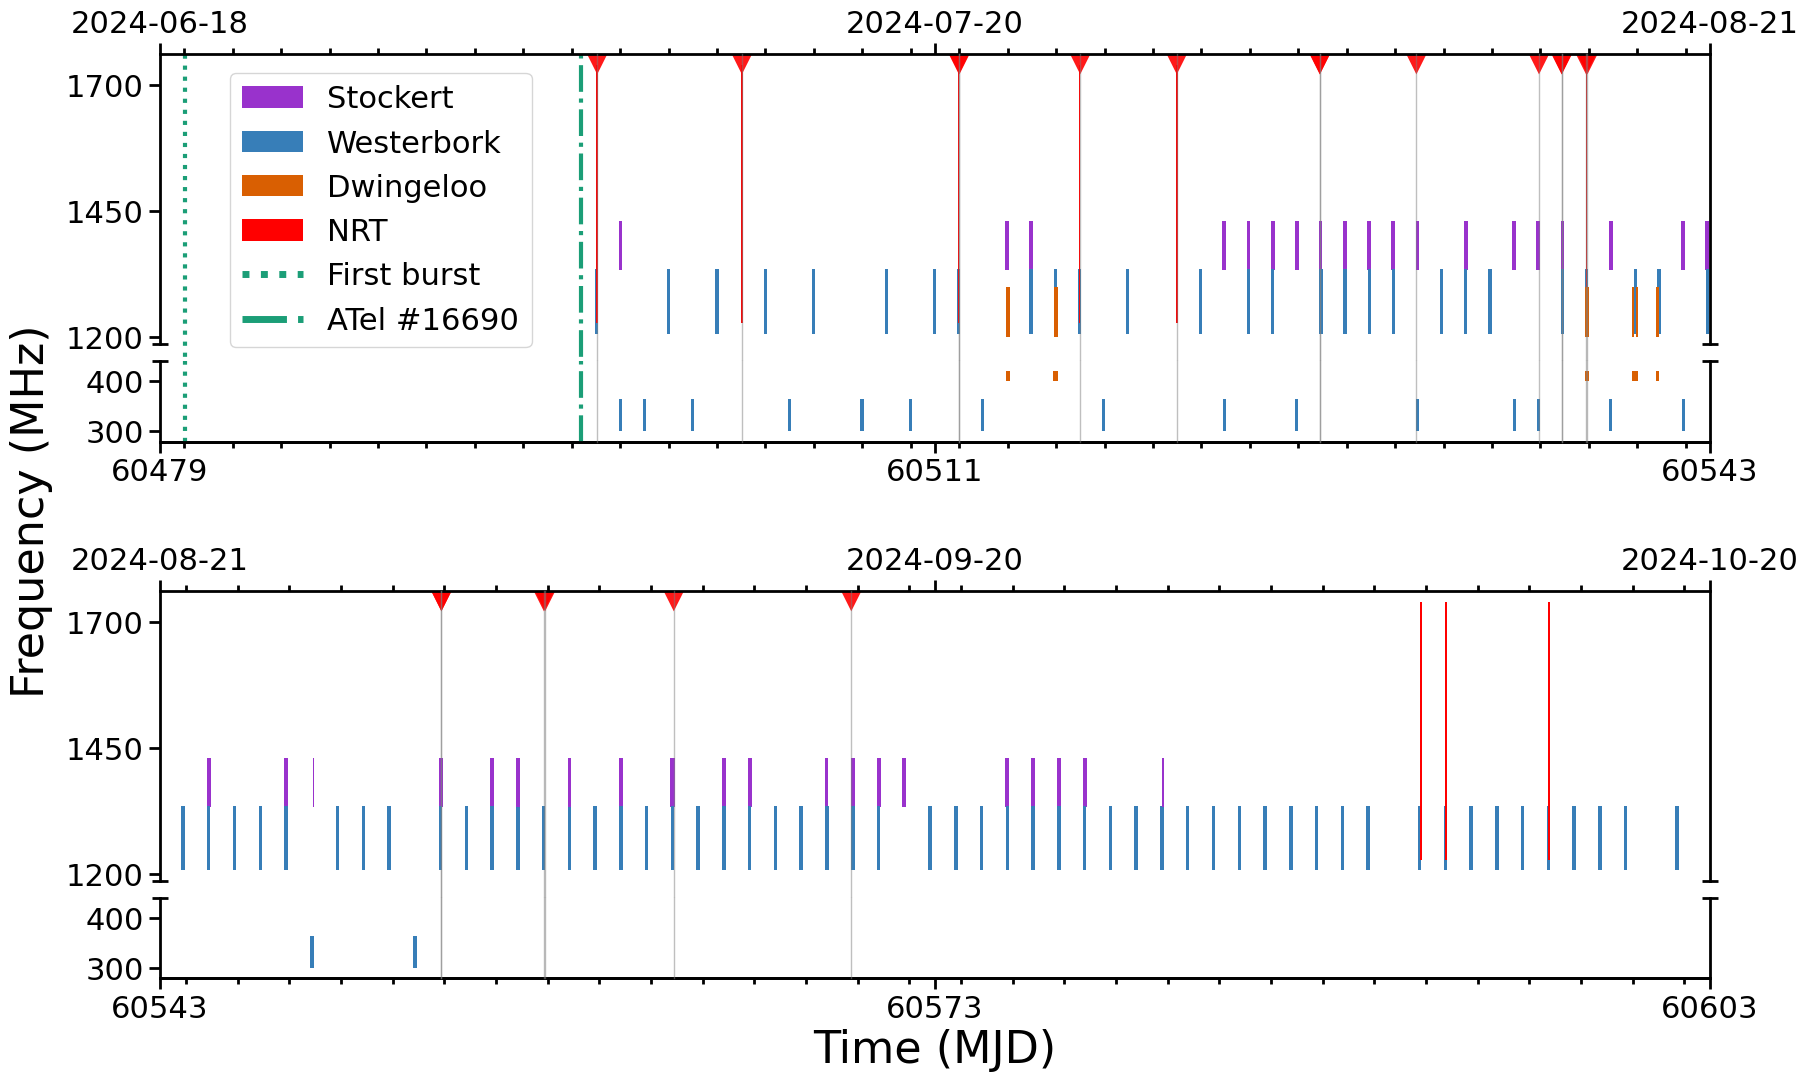

In [31]:
def observing_plot(df_reduced):

    colours = get_station_colors()
    
    # Set figure size
    width, height = 20, 12
    fig, (ax2, ax3, ax4, ax6, ax7) = plt.subplots(5, 1, figsize=(width, height), sharex=False,
        gridspec_kw={'height_ratios': (1, 1/3.58, 0.4, 1, 1/3.58)})
    fig.subplots_adjust(hspace=0)

    # Set spacing and limits
    space = 20
    l_low, l_high = 1207, 1740
    l_axes = [ax2, ax6]
    p_axes = [ax3, ax7]

    for ax in l_axes:
        ax.set_ylim(l_low - space, l_high + space)
        ax.set_yticks([1200, 1450, 1700])
        ax.spines['top'].set_visible(True)
        ax.spines['bottom'].set_visible(False)
        ax.tick_params(labeltop=True, labelbottom=False, bottom=False, top=True)
        
    for ax in p_axes:
        ax.set_ylim(300 - space, 420 + space)
        ax.set_yticks([300,400])
        ax.spines['top'].set_visible(False)
        ax.tick_params(labeltop=False, bottom=False, labelbottom=False)
        ax.xaxis.tick_bottom()

    # Create an invisible axis between ax3 and ax6
    ax4.set_visible(False)

    #Limits on the plot
    start_mjd = 60479
    bound_1 = 60543
    end_mjd = 60603

    if (start_mjd - bound_1)%2 != 0:
        print("WARNING, not even spaced days on top")

    if (bound_1 - end_mjd)%2 != 0:
        print("WARNING, not even spaced days on bottom")

    # Set x-limits for both sets of axes
    ax2.set_xlim(start_mjd, bound_1)
    ax6.set_xlim(bound_1, end_mjd)

    ax3.sharex(ax2)
    ax7.sharex(ax6)

    # Set specific dates on xticks for ax2 and ax6
    ax2.set_xticks([start_mjd, start_mjd + (bound_1 - start_mjd) / 2, bound_1])
    ax6.set_xticks([bound_1, bound_1 + (end_mjd - bound_1) / 2, end_mjd])
    ax3.tick_params(labeltop=False, labelbottom=False, bottom=False, top=False)
    ax7.tick_params(labeltop=False, labelbottom=False, bottom=False, top=False)

    # Set ISO date labels for ax2 and ax6 (UTC)
    for ax in [ax2,ax6]:
        times_top = ax.get_xticks()
        t_t = Time(times_top, format='mjd', scale='utc')
        mjd_isot_t = t_t.to_value('isot', 'date')
        ax.set_xticklabels(mjd_isot_t, rotation=0)

    # Set the secondary x-axis on ax3 and ax7 for MJD dates at the bottom
    secax3 = ax3.secondary_xaxis('bottom')
    mjd_dates = [int(mjd) for mjd in ax2.get_xticks()]
    secax3.set_xticks(mjd_dates)
    secax3.set_xticklabels(mjd_dates)  # Set MJD labels on the bottom of ax3

    # Set the secondary x-axis on ax7 for MJD dates at the bottom
    secax7 = ax7.secondary_xaxis('bottom')
    mjd_dates_ax6 = [int(mjd) for mjd in ax6.get_xticks()]
    secax7.set_xticks(mjd_dates_ax6)
    secax7.set_xticklabels(mjd_dates_ax6)  # Set MJD labels on the bottom of ax7

    #Main labels
    size_main_lbl = 32
    secax7.set_xlabel("Time (MJD)", fontsize=size_main_lbl)
    fig.text(0.05, 0.5, 'Frequency (MHz)', va='center', rotation='vertical', fontsize=size_main_lbl)
    
    # Draw diagonal lines for broken axes
    kwargs = dict(marker=[(-1, 0), (1, 0)], markersize=12,
                  linestyle="none", color='k', mec='k', mew=2, clip_on=False)
    ax2.plot([0, 1], [0, 0], transform=ax2.transAxes, **kwargs)
    ax3.plot([1, 0], [1, 1], transform=ax3.transAxes, **kwargs)
    ax4.plot([1, 0], [1, 1], transform=ax4.transAxes, **kwargs)
    ax6.plot([0, 1], [0, 0], transform=ax6.transAxes, **kwargs)
    ax7.plot([1, 0], [1, 1], transform=ax7.transAxes, **kwargs)
    fig.subplots_adjust(hspace=0.1)

    # # Add legend
    # legend_elements = [Patch(facecolor=colours['st'], label='Stockert'),
    #                    Patch(facecolor=colours['wb'], label='Westerbork'),
    #                    Patch(facecolor=colours['dw'], label='Dwingeloo'),
    #                   Patch(facecolor=colours['on'], label='NRT')]
    # ax2.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(0.04, 0.99), fontsize=22)

    # Legend elements: patches for telescopes, lines for detection and ATel
    legend_elements = [
        Patch(facecolor=colours['st'], label='Stockert'),
        Patch(facecolor=colours['wb'], label='Westerbork'),
        Patch(facecolor=colours['dw'], label='Dwingeloo'),
        Patch(facecolor="red", label='NRT'),
        Line2D([0], [0], color='#1b9e77', linestyle='dotted', linewidth=5, label='First burst'),
        Line2D([0], [0], color='#1b9e77', linestyle='dashdot', linewidth=5, label='ATel #16690')
    ]
    # Add legend
    ax2.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(0.035, 0.99), fontsize=22)

    # Plot observation data
    for i in range(len(df_reduced["mjd_start"])):
        tele = df_reduced["Telescope"][i]
        obs_code = df_reduced["obs_code"][i]
        mjd_s = df_reduced["mjd_start"][i]
        mjd_e = df_reduced["mjd_end"][i]
        low_c = df_reduced["low_c_l"][i]
        high_c = df_reduced["high_c_h"][i]
        bandwidth = df_reduced["bandwidth"][i]
        obs_time_d = df_reduced["rec_time_d"][i]

        if tele == "stk":
            lab, cc = "Stockert", colours['st']
        elif tele == "wb":
            lab, cc = "Westerbork", colours['wb']
        elif tele == "dw":
            lab, cc = "Dwingeloo", colours['dw']
        elif tele == "Nancay":
            lab, cc = "NRT", "red"
        
        for ax in [*l_axes, *p_axes]:

            #Visual trick to make one of the Nancay observations more visible
            if tele == "Nancay" and obs_time_d < 0.04:
                obs_time_d = 0.08
            rect = Rectangle((mjd_s, low_c), obs_time_d, height=bandwidth,
                             facecolor=cc, lw=0.0, edgecolor='k')
            ax.add_patch(rect)

    # Draw vertical lines of detectino MJDs
    df_mjds = df_obs_times()
    mjd_1 = df_mjds[df_mjds['mjd_tdb_inf_freq'].between(start_mjd, bound_1)]['mjd_tdb_inf_freq'].values
    mjd_2 = df_mjds[df_mjds['mjd_tdb_inf_freq'].between(bound_1, end_mjd)]['mjd_tdb_inf_freq'].values
    #line kwargs
    kwargs = dict(ymax=1, clip_on=False, ls='solid', color='grey', lw=1, alpha=0.5 ,zorder=3)

    for burst_mjd in mjd_1:
        ax2.scatter(burst_mjd, l_high, marker='v', color='red', s=200, alpha=0.9, edgecolor='none')
        ax2.axvline(x=burst_mjd, ymin=-0.2, **kwargs)
        ax3.axvline(x=burst_mjd, ymin=0, **kwargs)

    for burst_mjd in mjd_2:
        ax6.scatter(burst_mjd, l_high, marker='v', color='red', s=200, alpha=0.9, edgecolor='none')
        ax6.axvline(x=burst_mjd, ymin=-0.2, **kwargs)
        ax7.axvline(x=burst_mjd, ymin=0, **kwargs)

    mjd_meerkat = [60480.02848379630]
    for burst_mjd in mjd_meerkat:
        ax2.axvline(x=burst_mjd, ymin=-0.2, ymax=1, clip_on=False, ls='dotted', color='#1b9e77', lw=3)
        ax3.axvline(x=burst_mjd, ymin=0, ymax=1, clip_on=False, ls='dotted', color='#1b9e77', lw=3)

    mjd_meerkat = [60496.39583333334]
    for burst_mjd in mjd_meerkat:
        ax2.axvline(x=burst_mjd, ymin=-0.2, ymax=1, clip_on=False, ls='dashdot', color='#1b9e77', lw=3)
        ax3.axvline(x=burst_mjd, ymin=0, ymax=1, clip_on=False, ls='dashdot', color='#1b9e77', lw=3)

    for ax in [ax2, ax6]:
        ax.tick_params(which='minor', labeltop=False, labelbottom=False, bottom=False, top=True)
        ax.xaxis.set_minor_locator(MultipleLocator(2))
    
    # Set axis line width and tick params for all axes
    for ax in [*l_axes, *p_axes, secax3, secax7]: 
        for axis in ['top', 'bottom', 'left', 'right']:
            ax.spines[axis].set_linewidth(2)
            ax.tick_params(axis='y', which='major', direction='out', length=8, width=2, labelsize=22)
            ax.tick_params(axis='x', which='major', direction='out', length=8, width=2, labelsize=22)
            ax.tick_params(axis='x', which='minor', direction='out', length=4, width=2, labelsize=22)

    save_name = "observing_plot_meerkat_cmp_V4"
    plt.savefig(f"../plots/{save_name}.pdf", format = 'pdf', dpi=300, bbox_inches='tight')
    plt.savefig(f"../plots/{save_name}.png", facecolor='white', transparent=False, \
                format = 'png',bbox_inches='tight', dpi=300)
    
    plt.show()
    
observing_plot(df_reduced=df_reduced)